# 4. Linear Neural Networks for Classification

Most things from previous chapters will remain same, but loss function will change to a more appropriate one for _classification_ tasks. 

# 4.1 Softmax Regression

Regression for _how much/many_ kind of questions

_Classification_ problems focus on _which category_?

2 Types of Classification Problems (note in practice, distinction is not as clear since even when we care about hard assignment, we use models that make soft assignments to achieve such a goal)
1. Hard Assignments of examples to categories/classes.
2. Soft Assignments where we assess probabilities that each category applies to. 

There is also case of multi-class classiication (reccomended references saved to Word tracker). 

### 4.1.1 Classification

_one-hot encoding_ to represent categorical data (where component correspond to particular instance of category is set to 1 and all components are 0)

Recall softmax, partition functions, etc. arising from non-negativity of each probability (continuous or discrete) and normalizaton to 1. Also recall temperature corresponding to equalizing (high temp) or emphasizing low energy states (low temp)

Warning about exponentialing large values for softmax that can cause numerical over/underflow. Apparently deep learning frameworks take care of this automatically. Recall from 119B that only relative energy differences matter for probabilities, so probably something to do with that. 

### 4.1.2 Loss Function

Recall: _Cross-Entropy_ is negative of summation over (target/label times log (model prediction) ). Note that due to one-hot encoding (of single-class classification) of the target/label vector, all but 1 term will be 0. 

Note that loss is bounded by 0 on the lower end which can only happen if predicted correctly with absolute certainity, which can never happen because taking softmax result to 1 requires taking corresponding input to infinity, or all other outputs to negative infinity. 

General Case of Cross-Entropy Loss: Target vector of 1-hot encoding (say, (0, 0, 1) ) and a generic probability vector (say, (0.1, 0.2, 0.7) ). Math defined previously for total cross-entropy loss is still the same. 

### 4.1.3 Information Theory Basics

Shannon Entropy formula. Entropy is defined as the _expected suprisal_ when one assigned the correct probabilites that matches the underlying true data-generating process. The "suprisal" is quantified as: $$ \log \frac{1}{P(j)} = -\log P(j)$$

Entropy is level of suprise experienced by someone who know the true probability. Cross entropy from $P$ to $Q$ (written as $H(P, Q)$), is expected suprise of an observer with subjective probabilities $Q$ upon seeing data that was genertaed by distribution $P$. 
$$ H(P, Q) \equiv \sum_{j} -P(j) \log Q(j)$$
Note lowest possible cross entropy is when $Q=P$, i.e. observer has perfect knowledge of the data generating process. 

The cross-entropy classification objective function works as: 
1. Maximizing liklihood of observed data
2. Minimizing suprise to communicate labels 

### 4.1.4 Summary and Discussion

* Cross-entropy allows us to optimize over DISCRETE spaces. 
* Softmax tranforms neural network layer outputs to discrete probability distributions
* Derivative of cross-entropy loss combined with softmax behaves slosely to derivative of MSE, i.e. distance between target and prediction. 
* In practice for, fully-connected layer of $d$ inputs and $q$ outputs, the parametrization and computational cost is $\mathcal{O}(dq)$ which is quadratic and rather high in practice

### 4.1.5 Exercises

1. We can explore the connection between exponential families and softmax in some more depth.
   1. Compute the second derivative of the cross-entropy loss $l(\mathbf{y},\hat{\mathbf{y}})$ for softmax.
   2. Compute the variance of the distribution given by $\mathrm{softmax}(\mathbf{o})$ and show that it matches the second derivative computed above.
2. Assume that we have three classes which occur with equal probability, i.e., the probability vector is $(\frac{1}{3}, \frac{1}{3}, \frac{1}{3})$.
   1. What is the problem if we try to design a binary code for it?
   2. Can you design a better code? Hint: what happens if we try to encode two independent observations? What if we encode $n$ observations jointly?
3. When encoding signals transmitted over a physical wire, engineers do not always use binary codes. For instance, PAM-3 uses three signal levels $\{-1, 0, 1\}$ as opposed to two levels $\{0, 1\}$. How many ternary units do you need to transmit an integer in the range $\{0, \ldots, 7\}$? Why might this be a better idea in terms of electronics?
4. The Bradley–Terry model uses a logistic model to capture preferences. For a user to choose between apples and oranges one assumes scores $o_{\textrm{apple}}$ and $o_{\textrm{orange}}$. Our requirements are that larger scores should lead to a higher likelihood in choosing the associated item and that the item with the largest score is the most likely one to be chosen.
   1. Prove that softmax satisfies this requirement.
   2. What happens if you want to allow for a default option of choosing neither apples nor oranges? Hint: now the user has three choices.
5. Softmax gets its name from the following mapping: $\textrm{RealSoftMax}(a, b) = \log (\exp(a) + \exp(b))$.
   1. Prove that $\textrm{RealSoftMax}(a, b) > \mathrm{max}(a, b)$.
   2. How small can you make the difference between both functions? Hint: without loss of generality you can set $b = 0$ and $a \geq b$.
   3. Prove that this holds for $\lambda^{-1} \textrm{RealSoftMax}(\lambda a, \lambda b)$, provided that $\lambda > 0$.
   4. Show that for $\lambda \to \infty$ we have $\lambda^{-1} \textrm{RealSoftMax}(\lambda a, \lambda b) \to \mathrm{max}(a, b)$.
   5. Construct an analogous softmin function.
   6. Extend this to more than two numbers.
6. The function $g(\mathbf{x}) \stackrel{\textrm{def}}{=} \log \sum_i \exp x_i$ is sometimes also referred to as the log-partition function.
   1. Prove that the function is convex. Hint: to do so, use the fact that the first derivative amounts to the probabilities from the softmax function and show that the second derivative is the variance.
   2. Show that $g$ is translation invariant, i.e., $g(\mathbf{x} + b) = g(\mathbf{x})$.
   3. What happens if some of the coordinates $x_i$ are very large? What happens if they’re all very small?
   4. Show that if we choose $b = \mathrm{max}_i x_i$ we end up with a numerically stable implementation.
7. Assume that we have some probability distribution $P$. Suppose we pick another distribution $Q$ with $Q(i) \propto P(i)^\alpha$ for $\alpha > 0$.
   1. Which choice of $\alpha$ corresponds to doubling the temperature? Which choice corresponds to halving it?
   2. What happens if we let the temperature approach $0$?
   3. What happens if we let the temperature approach $\infty$?

Exercise #1 

(1) Second derivative of cross-entropy loss $l(y, \hat{y})$ for softmax can be found by first referring to the equation given earlier of: 
$$ \partial_{o_j} l(y, \hat{y}) = \frac{\exp(o_j)}{\sum_{k=1}^q \exp(o_k)} - y_j = \text{softmax}(o)_j - y_j = \hat{y}_j - y_j$$

First take the 2nd derivative w.r.t. $o_i$ ($i\neq j$) to get:
$$ \frac{ \frac{\partial}{\partial o_i} (\exp{o_j}) Z - \exp{o_j} (\frac{\partial Z}{\partial o_i})}{Z^2}  = \frac{0 - \exp(o_j) \exp(o_i) }{Z^2} = -\hat{y}_j \hat{y}_i $$

Next, take the 2nd derivative w.r.t. $o_j$ to get:
$$ \frac{ \frac{\partial}{\partial o_j} (\exp{o_j}) Z - \exp{o_j} \frac{\partial}{\partial o_j} Z }{Z^2} = \frac{\exp{o_j}}{Z} - \frac{\exp{o_j}\exp{o_j}}{Z^2} = \hat{y} ( 1 - \hat{y})$$

Interpret this as one of the predictions are increased in value, the value of all other predictions decrease. 

(2) Variance of softmax as variance of the one-hot vectors of the targets w.r.t. to the target prediction probabilities:
$$ [\operatorname{Cov}(Y)]_{ij} = \mathbb{E}[Y_i Y_j] - \mathbb{E}[Y_i]\mathbb{E}[Y_j] = \delta_{ij} \hat{p}_i - \hat{p}_i \hat{p}_j$$

See above how the 2nd derivative can be collapsed into a single expression w/ the kronecker delta. 

Exercise #2

To encode 3 classes in binary, we need to use 3 of the possible 4 strings (00, 01, 10, 11) and at 1/3 probability each, that works out for a Shannon entropy of: $ -\frac{1}{3}\log_2{\frac{1}{3}}-\frac{1}{3}\log_2{\frac{1}{3}}-\frac{1}{3}\log_2{\frac{1}{3}} \approx 1.58 $. However, having to encode in binary means we need 4 classes (00, 01, 10, 11) to cover the 3 classes, which means this works out to an entropy of $ -\frac{1}{4}\log_2{\frac{1}{4}}-\frac{1}{4}\log_2{\frac{1}{4}}-\frac{1}{4}\log_2{\frac{1}{4}}-\frac{1}{4}\log_2{\frac{1}{4}} = -\log_2{\frac{1}{4}}  = -\log_2{2^-2} = \log_2{2^2} = 2$, so there is $2-1.58\approx 0.42$ bits per observation wasted. 

Principle used to design better encoding scheme - make sure begining of code does not overlap with any other code (refer to PHYS 150 Lecture 7), so we use: 0, 10, 11 (to encode the 3 classes). Since they are of the same probability, this will result in an average code length of: $\frac{1}{3}{1} + \frac{1}{3}(2) + \frac{1}{3}(2) = \frac{5}{3} \approx 1.667$. Better than before, but still above theoretical limit. 

Use hitn of encoding 2 independent obervations / encoding $n$ observations jointly. Encoding 2 independent observations of 3, lead to 9 different sequences/pairs where each of them have the same prob of $\frac{1}{9}$. If using fixed length, we would have to use 4 bits (per pair, so works out to 2 per single observation, which is the naive one). Googling this, we can use a variable-length scheme (like in 150) of 7 sequences of three and 2 sequences of four, to get an average code length of: $\frac{7\cdot 3 + 2 \cdot 4}{9} \cdot \frac{1}{2} \approx 1.61 $ per single observation. 

Exercise #3 

2 Ternary units to encode an integer in the range of {0,...,7} (compared to 3 binary units). This might be a better for electronics to make use of limited physical resources like bandwidth, but have to compensate with conversion back to binary for computational purposes, and have batter noise tolerances compared to strict binary system. 

Exercise #4 
 
Given $o_{orange} \text{ and } o_{apple}$, if we put them as the only 2 options into a softmax function, we will find that the demoninator is the same, and the higher probability will be assigned to whichever $o_{fruit}$ is larger since $\exp{x}$ is a monotonic function. 

Same trend holds if a "neither" option is added asw. 

Exercise #5

1. Just raise both side to the power of $e$ to get rid of the logarithm on the LHS. From there, it is very obvious to see that the LHS will always be bigger than the RHS due to the extra term. 
2. Assume WLOG $a \geq b$. The difference then can be written as $\log{e^a + e^b} - a = \log{e^a (1-e^{b-a})} = \log{e^a} + \log{(1-e^{b-a})} - a = \log{(1-e^{b-a})}$ which shows that the difference can be driven asymptotically to 0, but never be 0. 
3. Again, WLOG assume $a \geq b$. Using the same strategy as above, we find that $\frac{1}{\lambda} \log{e^{\lambda a} (1 + \exp{(\lambda b - \lambda a)})}= \frac{1}{\lambda} \log{(e^{\lambda a})} + \frac{1}{\lambda} \log{(1 + \exp{\lambda ( b- a)})}=\log{(1 + \exp{(\lambda(b-a))})} > 0$ for $\lambda > 0$. 
4. Skip. 
5. Skip. 
6. Skip. 

Exercise #6

This is week 1 of Physics 119B. Takeaway - for probabilities resultant from partition function, only the relative energy differences matter, so you can adjust all energies up or down together to prevent overflow/underflow and ensure numerical stability/accuracy and still have the same resultant probability distribution. 

Exercuse #7

1. $\alpha = \frac{1}{2}$ corresponds to doubling the temperature
2. When temperature approaches 0, then the probability distribution concentrates on the loweset energy state (i.e. the most probable outcome b4 cooling becomes more probable)
3. When temperature approaches $\infty$, the probability distribution approaches uniformity. 

# 4.2 Image Classification Dataset

MNIST has 60,000 images of $28 \times 28$ resolution with a test set of an additional 10,000 images. Used to be hard, but now is not. ImageNet is now popular, but kinda big for introductory educational purposes yet. Will be using Fashion-MNIST which is 10 categories of $28\times 28$ resolution images. 

In [122]:
%matplotlib inline
import time
import torch
import torchvision
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

### 4.2.1 Loading the Dataset

Due to popularity of Fashion-MNIST dataset, major frameworks provide pre-processed versions of it. Can download and read it into memory using built-in framework utilities. 

In [129]:
class FashionMNIST(d2l.DataModule):  
    """The Fashion-MNIST dataset."""
    def __init__(self, batch_size=64, resize=(28, 28)):
        super().__init__()
        self.save_hyperparameters()
        trans = transforms.Compose([transforms.Resize(resize), transforms.ToTensor()])
        self.train = torchvision.datasets.FashionMNIST(root=self.root, 
                                                       train=True, 
                                                       transform=trans, 
                                                       download=True)
        self.val = torchvision.datasets.FashionMNIST(root=self.root, 
                                                     train=False, 
                                                     transform=trans, 
                                                     download=True)
        
    def text_labels(self, indices):
        """Return text labels."""
        labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
        return [labels[int(i)] for i in indices]
    
    def get_dataloader(self, train):
        data = self.train if train else self.val
        return torch.utils.data.DataLoader(data, 
                                           self.batch_size, 
                                           shuffle=train,
                                           num_workers=self.num_workers)
    
    def visualize(self, batch, nrows=1, ncols=8, labels=[]):
        X, y = batch
        if not labels:
            labels = self.text_labels(y)
        d2l.show_images(X.squeeze(1), nrows, ncols, titles=labels)

In [130]:
# Will download the first time (indicated in output for 1st run)
data = FashionMNIST(resize=(32, 32))
len(data.train), len(data.val)

(60000, 10000)

In [131]:
# 32 x 32 pixels, 1 color channel (grascale). 
# CONVENTION: (# channels, height, width)
data.train[0][0].shape

torch.Size([1, 32, 32])

In [138]:
image, label = data.train[0]  
image, image.shape, label

(tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]]),
 torch.Size([1, 32, 32]),
 9)

Note, modern images have 3 color channels (RBG) and hyperspectral images can have access of 100 channels (HyMap sensor apparently has 126). 

### 4.2.2 Reading a Minibatch

Use built-in iterator rather than creating one from scratch. Recall at each iteration, data iterator will read a minibatch of data with size _batch_size_, with order of examples shuffled. 

Added the _get_dataloader_ method above in the class definition (add_to_class decorator makes it hard to keep track of things). 

In [84]:
X, y = next(iter(data.train_dataloader()))
print(X.shape, X.dtype, y.shape, y.dtype)

torch.Size([64, 1, 32, 32]) torch.float32 torch.Size([64]) torch.int64


In [85]:
# Notice that even for a built-in loader, it is not very fast. However, this is fine since processing 
# images with a deep network will take longer than said load time, and thus the network will not be 
# I/O bound during training
tic = time.time()
for X, y in data.train_dataloader():
    continue
f'{time.time() - tic:.2f} sec'

'2.57 sec'

In [86]:
tic = time.perf_counter()
for X, y in data.train_dataloader():
    continue
f'{time.perf_counter() - tic:.2f} sec'

'2.60 sec'

### 4.2.3 Visualization

Added visualization method above to class definition. 

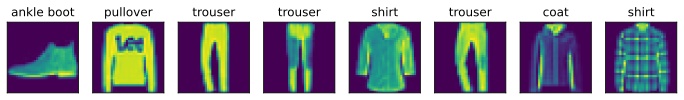

In [87]:
batch = next(iter(data.val_dataloader()))
data.visualize(batch)

### 4.2.4 Summary

### 4.2.5 Exercises

Exercise #1

Previously was around ~2.5 seconds with batch_size=64

With _batch_size_=1, data load time is ~11 seconds. 

Other aspects of loading operation are still efficient, so does increase by full factor of 64. 

Exercise #2

I'll come back to this later. 



Exercise #3

Theres a lot of datasets in torchvision: https://docs.pytorch.org/vision/main/datasets.html

# 4.3 The Base Classification Model

This section will focus on providing a base class for classification to simplify future code.

In [88]:
import torch
from d2l import torch as d2l

### 4.3.1 The _Classifier_ Class

In the _validation_step_ method, we report both the loss value & classification accuracy on a validation batch. We draw an update for every _num_val_batches_ batches. This will generate the averaged loss and accuracy on the entire validation data. Note - the average numbers are not exact if the final batch contains fewer examples, but we will ignore this minor difference to keep the code simple. 

By deafult, we use a stochastic gradient descent optimizer operating on minibatches 

In [147]:
class Classifier(d2l.Module):  
    """The base class of classification models."""
    def validation_step(self, batch):
        Y_hat = self(*batch[:-1])
        self.plot('loss', self.loss(Y_hat, batch[-1]), train=False)
        self.plot('acc', self.accuracy(Y_hat, batch[-1]), train=False)

    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), lr=self.lr)
    
    def accuracy(self, Y_hat, Y, averaged=True):
        """Compute the number of correct predictions."""
        Y_hat = Y_hat.reshape((-1, Y_hat.shape[-1]))
        preds = Y_hat.argmax(axis=1).type(Y.dtype)
        compare = (preds == Y.reshape(-1)).type(torch.float32)
        return compare.mean() if averaged else compare

### 4.3.2 Accuracy

Given a predicted probability distribution $\hat{y}$, for hard classification topics we must choose a single category, so we just choose the highest probability. The classification accuracy is the percentage of all predictions that are correct. Although it is difficult to optimize directly for accuracy (since it is non-differentiable), it is the end-result we care most about so it must always be reported. 

Accuracy is calculated as follows: 
* If $\hat{y}$ is a matrix, we assume taht the 2nd dimension stores predictino scores for each class. 
* We use _argmax_ to btain predicted class by fetchng the index of said entry with the largest probability. 
* Make sure to convert $\hat{y}$ data type to match $y$'s. 
* Result will be a tensor that contains entires of 0's (falses) and 1's (true). Taking the sum yields the number of correct predictions. 


The _accuracy_ method has been added to the _Classifier_ class itself directly. 

### 4.3.3 Summary

### 4.3.4 Exercises

1. Denote by $L_\textrm{v}$ the validation loss, and let $L_\textrm{v}^\textrm{q}$ be its quick and dirty estimate computed by the loss function averaging in this section. Lastly, denote by $l_\textrm{v}^\textrm{b}$ the loss on the last minibatch. Express $L_\textrm{v}$ in terms of $L_\textrm{v}^\textrm{q}$, $l_\textrm{v}^\textrm{b}$, and the sample and minibatch sizes.

2. Show that the quick and dirty estimate $L_\textrm{v}^\textrm{q}$ is unbiased. That is, show that $E[L_\textrm{v}] = E[L_\textrm{v}^\textrm{q}]$. Why would you still want to use $L_\textrm{v}$ instead?

3. Given a multiclass classification loss, denoting by $l(y,y')$ the penalty of estimating $y'$ when we see $y$ and given a probabilty $p(y \mid x)$, formulate the rule for an optimal selection of $y'$. Hint: express the expected loss, using $l$ and $p(y \mid x)$.


# 4.4 Softmax Regression Implementation from Scratch

Walk through it manually from scratch for educational purposes. Will be using other components from linear regressino section incl. the training loop. 

In [148]:
import torch
from d2l import torch as d2l

class Trainer(d2l.HyperParameters):  #@save
    """The base class for training models with data."""
    def __init__(self, max_epochs, num_gpus=0, gradient_clip_val=0):
        self.save_hyperparameters()
        assert num_gpus == 0, 'No GPU support yet'

    def prepare_data(self, data):
        self.train_dataloader = data.train_dataloader()
        self.val_dataloader = data.val_dataloader()
        self.num_train_batches = len(self.train_dataloader)
        self.num_val_batches = (len(self.val_dataloader)
                                if self.val_dataloader is not None else 0)

    def prepare_model(self, model):
        model.trainer = self
        model.board.xlim = [0, self.max_epochs]
        self.model = model

    def fit(self, model, data):
        self.prepare_data(data)
        self.prepare_model(model)
        self.optim = model.configure_optimizers()
        self.epoch = 0
        self.train_batch_idx = 0
        self.val_batch_idx = 0
        for self.epoch in range(self.max_epochs):
            self.fit_epoch()

    def fit_epoch(self):
        raise NotImplementedError

### 4.4.1 The Softmax

Need to do the following 3 steps for softmax:
1. Exponentiation of each term
2. Sum over each row to compute normalization constant
3. Divide each row by normalization constant

In [149]:
# Recall how summing along an axis works in PyTorch
X = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print("X is: ", X, "\nof shape", X.shape)
print("\nX.sum(axis=0, keepdims=True) is: \n ", X.sum(axis=0, keepdims=True), "\nof shape", X.sum(axis=0, keepdims=True).shape)
print("\nX.sum(axis=1, keepdims=True) is: \n", X.sum(axis=1, keepdims=True), "\nof shape", X.sum(axis=1, keepdims=True).shape)

X is:  tensor([[1., 2., 3.],
        [4., 5., 6.]]) 
of shape torch.Size([2, 3])

X.sum(axis=0, keepdims=True) is: 
  tensor([[5., 7., 9.]]) 
of shape torch.Size([1, 3])

X.sum(axis=1, keepdims=True) is: 
 tensor([[ 6.],
        [15.]]) 
of shape torch.Size([2, 1])


In [150]:
X[0], X[1], X[0][1]

(tensor([1., 2., 3.]), tensor([4., 5., 6.]), tensor(2.))

In [151]:
# Tensor comes in as (batch_size, num_classes). Want to sum all the predicted probabilities, not along batch_size
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(axis=1, keepdims=True) 
    return X_exp / partition # Broadcasting applied here

In [152]:
# Test it out
X = torch.rand( (2, 5) )
X_prob = softmax(X)
X_prob, X_prob.sum(axis=1), X_prob.sum(axis=1).shape # notice no keepdims here

(tensor([[0.1812, 0.1099, 0.2123, 0.2436, 0.2530],
         [0.1354, 0.1816, 0.2151, 0.2510, 0.2169]]),
 tensor([1., 1.]),
 torch.Size([2]))

### 4.4.2 The Model

Will be using linear regresio where our inputs are vectors of length 784 ($28 \times 28$) (CNN's introduced later will exploit spatial structure in a more satisfying way). 

In [153]:
class SoftmaxRegressionScratch(Classifier):
    def __init__(self, num_inputs, num_outputs, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W = torch.normal(0, sigma, size=(num_inputs, num_outputs), requires_grad=True)
        self.b = torch.zeros(num_outputs, requires_grad=True)

    def parameters(self):
        return [self.W, self.b]
    
    def forward(self, X):
        # Reshape features to match inputs of weight matrix and infer number of rows 
        X = X.reshape( (-1, self.W.shape[0]) ) 
        return softmax(torch.matmul(X, self.W) + self.b)

    def loss(self, y_hat, y):
        return cross_entropy(y_hat, y)

### 4.4.3 The Cross-Entropy Loss

* **Recall cross-entropy takes negative-log-liklihood assigned to the true label**. This will result in high loss for low probabilites (since undesirable) and low losses for high probablities (desirable). Intuitively (and recall rigorously from previous sections) increasing probabilities for correct labels will automatically move down predictions for incorrect labels (since dealing with probablities, not "energy" here)
* Avoid for-loops and use indexing method (for efficiency) - one-hot encoding in the target label allows us to select matching term to $\hat{y}$ easily
* Example below: sample data with 2 examples of predicted probabilities over 3 classes and corresponding labels $y$. 
* Correct labels are 0, 2 (i.e. first & third class). Using $y$ as the indicies fo the probabilities in $\hat{y}$, we can pick out terms efficiently

_cross_entropy_ is defined globally, but _loss_ method is directly added to in SoftmaxRegressionScratch class above (instead of _add_to_class_ decorator)

In [ ]:
# select the predicted probabilities for the correct classes from model's probability predictions
y     = torch.tensor([0, 2])  # Indices of the correct labels
y_hat = torch.tensor([ [0.1, 0.3, 0.6], [0.3, 0.2, 0.5] ])
# The list list [0, 1] is generally just supposed to be a list of row indices [0, ..., n-1] 
# where n is the number of rows in y_hat, but here we only have 2 rows so we just use [0, 1]
y_hat[ [0, 1], y]  # Picks out y_hat[0][0] and y_hat[1][2]

tensor([0.1000, 0.5000])

In [155]:
def cross_entropy(y_hat, y):
    return -torch.log(y_hat[list(range(len(y_hat))), y]).mean()

cross_entropy(y_hat, y)

tensor(1.4979)

In [161]:
import numpy as np
-np.mean([np.log(0.1),  np.log(0.5)])

1.4978661367769954

### 4.4.4 Training

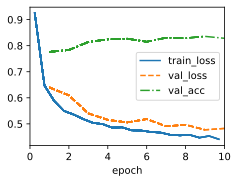

In [105]:
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegressionScratch(num_inputs=784, num_outputs=10, lr=0.1)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

### 4.4.5 Prediction

Now that model is trained, it is ready to classify some images

We are especially interested when the model labeled them incorrectly

In [ ]:
# Make predictions
X, y = next(iter(data.val_dataloader()))
preds = model(X).argmax(axis=1)
preds.shape

torch.Size([256])

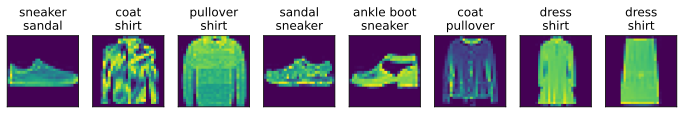

In [ ]:
# View some incorrect predictions
# True labels on top
# Incorrectly predicted labels on bottom
wrong = preds.type(y.dtype) != y
X, y, preds = X[wrong], y[wrong], preds[wrong]
labels = [a+'\n'+b for a, b in zip(
    data.text_labels(y), data.text_labels(preds))]
data.visualize([X, y], labels=labels)

### 4.4.6 Summary

### 4.4.7 Exercises

1. In this section, we directly implemented the softmax function based on the mathematical definition of the softmax operation. As discussed in this can cause numerical instabilities.
    1. Test whether _softmax_ still works correctly if an input has a value of $100$.
    1. Test whether _softmax_ still works correctly if the largest of all inputs is smaller than $-100$.
    1. Implement a fix by looking at the value relative to the largest entry in the argument.
1. Implement a _cross_entropy_ function that follows the definition of the cross-entropy loss function $\sum_i y_i \log \hat{y}_i$.
    1. Try it out in the code example of this section.
    1. Why do you think it runs more slowly?
    1. Should you use it? When would it make sense to?
    1. What do you need to be careful of? Hint: consider the domain of the logarithm.
1. Is it always a good idea to return the most likely label? For example, would you do this for medical diagnosis? How would you try to address this?
1. Assume that we want to use softmax regression to predict the next word based on some features. What are some problems that might arise from a large vocabulary?
1. Experiment with the hyperparameters of the code in this section. In particular:
    1. Plot how the validation loss changes as you change the learning rate.
    1. Do the validation and training loss change as you change the minibatch size? How large or small do you need to go before you see an effect?


Exercise #1

Come back later

Exercise #2

Come back later

Exercise #3

Perhaps you can return the top-3 or top-5 prediction categories. 

Exercise #4

Softmax regrsesion for predicting the next word based on some features, a large vocabulary might cause normalization issues since we need to sum over the entire vocab list for every word. There would also be an imbalanced representation of commonly occuring words vs rarer words. 


Exercise #5 

Come back later

# 4.5 Concise Implementatino of Softmax Regression

In [109]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

### 4.5.1 Defining the Model

In [ ]:
class SoftmaxRegression(d2l.Classifier):  
    """The softmax regression model."""
    def __init__(self, num_outputs, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(),
                                 nn.LazyLinear(num_outputs))

    def forward(self, X):
        return self.net(X)

### 4.5.2 Softmax Revisited

Single precision floating point numbers approximately cover $10^{-38} \text{to} 10^{38}$, which results in practical logit range restriction of $o \in [-90, 90]$. One way (mentioned earlier multiple times asw) is to substract the max logit $(o_{max})$ from all logits. This will give us: 

$$ \hat{y} = \frac{\exp{o_j}}{\sum_k \exp{o_k}} = \frac{\exp(o_j - o_{max})}{\sum_k \exp{(o_k - o_{max})}}$$

We know that for a classification problem among $q$-classes, the demoninator (i.e. normalization constant) will be contained in the interval $[1, q]$, and that the numerator never exceeds $1$, thus solving the overflow/underflow issue. 

At this point, we note that once the softmax computes probabilities, we have to take the log of it to calculate the cross-entropy loss. We look at the softmax formula, and then just apply logarithim right now to see what happens: 

$$ \log{\hat{y_k}}  = \log{\frac{\exp(o_j - o_{max})}{\sum_k \exp(o_k - o_{max})}} = o_j - o_{max} - \log{\sum_k \exp(o_k - o_{max})}$$

If we want the probabilities from the softmax function, we can keep it, but we note that we can bypass the softmax entirely and avoid any possibility of overflow/underflow by just calculating the loss with the logits themselves. 

In [ ]:
@d2l.add_to_class(d2l.Classifier)  
def loss(self, Y_hat, Y, averaged=True):
    Y_hat = Y_hat.reshape((-1, Y_hat.shape[-1]))
    Y = Y.reshape((-1,)) # Flatten entire thing to 1D tensor for cross_entropy
    return F.cross_entropy(
        Y_hat, Y, reduction='mean' if averaged else 'none')

### 4.5.3 Training

Train with Fashion-MNIST images, flattedned to 784-dimension vectors for image inputs

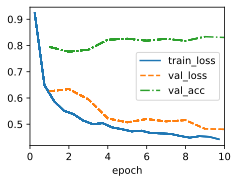

In [118]:
# Original Textbook
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegression(num_outputs=10, lr=0.1)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

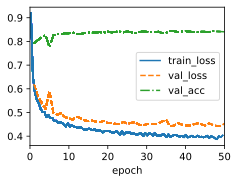

In [ ]:
# Exercise 3
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegression(num_outputs=10, lr=0.1)
trainer = d2l.Trainer(max_epochs=50)
trainer.fit(model, data)

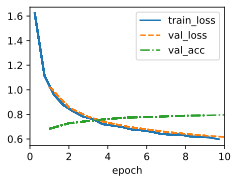

In [119]:
# Exercise 4 lr=0.01
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegression(num_outputs=10, lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

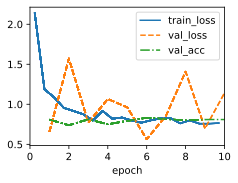

In [120]:
# Exercise 4 lr=0.5
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegression(num_outputs=10, lr=0.5)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

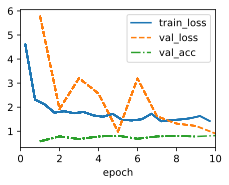

In [121]:
# Exercise 4 lr=1.0
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegression(num_outputs=10, lr=1.0)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

### 4.5.4 Summary

### 4.5.5 Exercises

1. Deep learning uses many different number formats, including FP64 double precision (used extremely rarely), FP32 single precision, BFLOAT16 (good for compressed representations), FP16 (very unstable), TF32 (a new format from NVIDIA), and INT8. Compute the smallest and largest argument of the exponential function for which the result does not lead to numerical underflow or overflow.

1. INT8 is a very limited format consisting of nonzero numbers from $1$ to $255$. How could you extend its dynamic range without using more bits? Do standard multiplication and addition still work?

1. Increase the number of epochs for training. Why might the validation accuracy decrease after a while? How could we fix this?

1. What happens as you increase the learning rate? Compare the loss curves for several learning rates. Which one works better? When?

Exercise #1

https://en.wikipedia.org/wiki/IEEE_754 (not signed X-bits)

1. FP64 Double Precision: $10^{-308} \text{ to } 10^{308} \rightarrow \text{max exponent magnitude }\approx \pm 709$
    1. $\pm 308 \log{(308)}$
1. FP32 Single Precision: $ 1.2 \times 10^{-38}  \text{ to } 3.4 \times 10^{38} \rightarrow \text{max exponent magnitude } -94 \text{ to } 134$ 
1. BFLOAT16: 
    1. Same 16 bits as as FP16, but uses more bits for exponents so has roughly same range as FP32, at the cost of precision w.r.t. to FP32. 
1. FP16: $\approx 6.1 \times 10^{-5} \text{ to } 65,000 \rightarrow \text{max exponent magnitude } -9.7 \text{ to }  11$
1. TF32: Same as FP32 here. 
    1. 19 bits per number, 1 for the sign, 8 for exponent (same as FP32), and 10 manitissa bits
1. INT8: $-128 \text{ to } 127$ (assuming signed, since not uint8). Max exponent $ \approx 4.84 $. IDT a min exp applies here, since it is unable to represent anything other than integers here.  


Exercise #2

IG here by int8 they mean unsigned int8 so $1 \text{ to } 255$. Instead of treating the treating the available 8 bits as unsigned 8 bits for representing integers exactly, use them as a quasi-floating point operations (with possible a scaling factor asw) $x = c \cdot b^k$ where $b$ is the base, $c$ is the scaling factor, and $k$ is the value stored in int8. 

Standard Multiplication: (assuming no scaling factor)
* Say $x = 2^a$ and $y = 2^b$. 
* $x \cdot y = 2^a \cdot 2^b = 2^{a+b}$, so standard multiplication still works by just adding in exponential sapce

Standard Addition: (assuming no scaling factor)
* Again, say $x = 2^a$ and $y = 2^b$. 
* $x + y = 2^a + 2^b$
* Need to convert back to linear space, add, then convert back to exponential space

Exercise #3

In textbook kept 10 epochs and validation accuracy started around $\approx 78\%$ and rose and converged to around $\approx 83\%$

With epochs increased to 50, the validation and training kept going lower (albeit slower than earlier epochs) but the validation accuracy held at $\approx 85\%$. If the validation accuracy decreased after a while that would indicate that the model has begun to overfit to the training set. We could fix this by terminating training earlier (or less epochs)

Exercise #4

Original lr=0.1. 

Smaller lr=0.01 results in slightly slower convergence but does not cause other issues. 

Larger lr=0.5, 1.0 show instability as the training/validatoin loss go up and down drastically between epochs/evaluations since due to the relatively large lr, the model dosen't smoothly descend down a local minimum but "bounces" around it

# 4.6 Generalization in Classification

1. How many test examples do we need to give a good estimate of accuracy of classifier on underlying population
1. What happens if we keep evaluating models on the same test repeatedly
1. Why should we expect that fitting linear models to training set should fare any better than naive memorization scheme

* Possible to guarantee generalization a priori - desired upper bound on generalizatio gap $\epsilon$ can often determine some required number of samples $n$ s.t. if our training set has at least $n$ samples, then our empirical error will lie within $\epsilon$ of the true error _for any data generating distribution_
* Note - these are of limited practical utility since such generalization theory requires very large # of examples (trillions or more), but empirically we find that for most tasks of interest, deep neural entworks generalize well with far fewer examples 
* Typically ignore such theoretical guidelines and prefer empirical evaluations based on what generalized well on similar problems in past 



### 4.6.1 The Test Set

* Consider fixed classifier $f$
* Consider dataset $\mathcal{D} = {(\mathbf{x}^{(i)},y^{(i)})}_{i=1}^n$ that was NOT used ot train the classifier $f$
* Empirical error ($\epsilon_{\mathcal{D}}$) of classifier $f$ on $\mathcal{D}$ is fraction of instances for which the prediction $f(\mathbf{x}^{(i)})$ disagree with true label $y^{(i)}$ ans is defined by: 

$$\epsilon_\mathcal{D}(f) = \frac{1}{n}\sum_{i=1}^n \mathbf{1}(f(\mathbf{x}^{(i)}) \neq y^{(i)}).$$

* Population Error - expected fraction of examples in underlying population (the distribution $P(X, Y)$ characterized by pdf $p(x, y)$) for which the classifer disagrees with the true label:

$$\epsilon(f) = E_{(x,y) \sim P} \mathbf{1}(f(x) \neq y) = \int \int \mathbf{1}(f(x)\neq y)p(x, y) \text{dxdy}$$

* Note, we cannot actually know/measure $\epsilon(f)$
* Since test set $\mathcal{D}$ is statistically representative of underlying population, we can view $\epsilon_{\mathcal{D}}$ as statistical estimator of population error $\epsilon(f)$
* Estimating population error is a problem of mean estimation - since $\epsilon_\mathcal{D}(f)$ is the sample average and quantity of interest ($\epsilon(f)$) is an expectaton (of the random variable in summand)
* Recall - Central Limit Theorem says whenever we have $n$ random samples drawn from a distribution with a mean $\mu$ and std of $\sigma$, then as the number of samples we draw converges to infinity, then then the sample mean ($\hat{\mu}$) converges to the true mean ($\mu$) and with standard deviation (of the sample mean) of $\frac{\sigma}{\sqrt{n}}$
* Takeaway: Our test error ($\epsilon_\mathcal{D}(f)$) will approach the true error ($\epsilon(f)$) at a rate of $\mathcal{O}(1/\sqrt{n})$
    * To reduce test error by factor of 100 (from arbitrary starting point), must increase 10,000 times larger test set

* Go back to random variable summed: $\mathbf{1(f(X) \neq Y)}$ is restricted to values $[0, 1]$ and thus is a Bernoulli random variable. If the summand is 1 it means it has made an error, so "success" in this context is when $f(x) \neq Y$, which is the true error ($\epsilon(f)$)
    * $\text{Variance} = \sigma^2 = \epsilon(f)(1-\epsilon(f))$
    * Variance is highest when true error rate is close to $0.5$, and lowest when true error is close to 0 or 1
    * Asymptotic Standard Deviatino of estimate $\epsilon_\mathcal{D}(f)$ of the error $\epsilon(f)$ cannot be any greater than $\sqrt{\frac{0.25}{n}}$ (from assuming worst case of true error rate of $0.5$)
    * $\text{std}=\sqrt{\frac{\epsilon(f)(1-\epsilon(f))}{n}} \leq \sqrt{\frac{0.25}{n}}$
* If we want our test set error to approximate the population error s.t. one std of the test set error 1 standard deviation corresponds to an interval of $\pm 0.01$ ($1\%$), we should collect roughly 2500 samples. If we want 2 standard deviations (s.t. we can be 95% confident that $\epsilon_\mathcal{D}(f)\in \epsilon(f) \pm 0.01$), then wen need 10,000 samples
* Note all previous analysis was for asymptotic behavior
* Since our random variable (error) is bounded, we can obtain valid finite sample bounds by applying Hoeffding inequality to get: 

$$P(\epsilon_\mathcal{D}(f) - \epsilon(f) \geq t)< \exp{(-2nt^2)}$$
* To get same 95% (2 std) garuntee as earlier, we need 15,000 examples

### 4.6.2 Test Set Reuse

* Recall/Note - all preliminary analysis, hyperparameter tuning, selecting of model architectures shuold be optimized on validation set
* When testing multiple classifiers on test set, there is possiblity one or more of the classifier results are misleading, since "garuntees" from before are probabalistic garuntees, not absolute
* once information on test set has leaked to modeler, it can never a "true test set" again - "adaptive overfitting"

### 4.6.3 Statistical Learning Theory

* Test sets are all we have
* Rarely, if ever have a "true test set"
* We also can never have absolute faith on numbers/results aswe
* Statistical Learning Theory: Mathematical subfield of ML focusing on why/when models trained on empirical data can/will generalize to unseen data
    * One goal is to bound the generalization gap that relates properties of model class to number of samples in dataset
* Recall previously we fixed our classifier $f$
    * Issues arise when comparing multiple (esp many) classifier due to probability some of their test set results are misleadin
    * If we pick said classifier and seriously underestimate population error is a big no no
* One possible solution - analytic tools for proving uniform convergence i.e. with high probability that empirical error rate for every classifier $f \in \mathcal{F}$ will SIMULTANEOUSLY converge to its true error rate
    * How would we know with at least probability $1-\delta$ (obv want $\delta$ to be small) that no classifier's error rate $\epsilon(f)$ for $\forall f \in \mathcal{F}$ will be mis-estimated by more than an amount $\alpha$
    * Note - we cannot make such a statement for all model classes $\mathcal{F}$. Counterexample of memorization machines that have 0 empirical error but never outperform random guessing on testset
    * Memorizer Class: Too flexible but no uniform convergence could hold 
    * Fixed Classifier Class: Generalized perfectly - but fits neither the training data nor test data
* Bias-Variance Tradeoff: Flexible models (higher variance) model classes that fit training data better (low bias), but risk overfitting w.r.t. rigid (lower variance) models that generalize well but risk underfitting (high bias)
    * bias = loss
* Some discussin on Vapnik-Chervonekis (VC) dimension 

### 4.6.4 Summary

### 4.6.5 Exercises

1. If we wish to estimate the error of a fixed model $f$ to within $0.0001$ with probability greater than 99.9%, how many samples do we need?
1. Suppose that somebody else possesses a labeled test set $\mathcal{D}$ and only makes available the unlabeled inputs (features). Now suppose that you can only access the test set labels by running a model $f$ (with no restrictions placed on the model class) on each of the unlabeled inputs and receiving the corresponding error $\epsilon_\mathcal{D}(f)$. How many models would you need to evaluate before you leak the entire test set and thus could appear to have error $0$, regardless of your true error?
1. What is the VC dimension of the class of fifth-order polynomials?
1. What is the VC dimension of axis-aligned rectangles on two-dimensional data?

Exercise #1

* Recall: $ 1 \text{ std} = \sqrt{\frac{0.25}{n}}$
* $99.9\% \geq \approx $ corresponds to z-score of $\approx 3.3$
$$0.0001 \geq 3.3 \cdot \sqrt{\frac{0.25}{n}} \rightarrow n \geq 272,250,000 $$

Exercise #2

* I have a feeling this problem is only answerable if its like the VC dimension thing and the labels ahve to be binary...

* Test set leakage problem 

* (COME BACK TO THIS LATER)

Exercise #3

* Fifth order polynomials have 6 degrees of freedom (think 5 degrees, 5 roots thus 5 pivots points)

Exercise #4

* Will be interpreting this as inside/outside rectangle (rather than "splitting with a line")
* VC Dimensino of 4 
    * 5 dosen't work in 2d data/plane

# 4.7 Environment and Distribution Shift

### 4.7.1 Types of Distribution Shift

### 4.7.2 Examples of Distribution Shift

### 4.7.3 Correction of Distribution Shift

### 4.7.4 A Taxonomy of Learning Problems

### 4.7.5 Fairness, Accountability, and Transparency in Machine Learning

### 4.7.6 Summary

### 4.7.7 Exercises

1. What could happen when we change the behavior of a search engine? What might the users do? What about the advertisers?
1. Implement a covariate shift detector. Hint: build a classifier.
1. Implement a covariate shift corrector.
1. Besides distribution shift, what else could affect how the empirical risk approximates the risk?